# Lançamento

In [137]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import import_ipynb
import forcas_foguete as ff
import copy

0.0 | 0.0 | 177509.40123957643
Mach = 1.1
CD = 0.429
-0.0 | -0.0 | -0.0


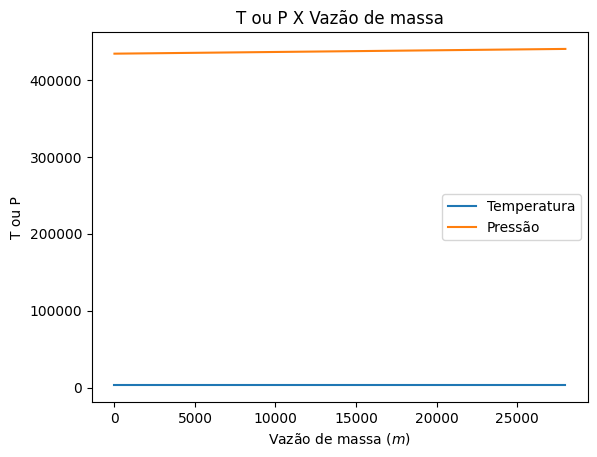

ModuleSpec(name='forcas_foguete', loader=<import_ipynb.NotebookLoader object at 0x00000219ED2FD940>, origin='forcas_foguete.ipynb')

In [138]:
import importlib

importlib.reload(ff)

## Exaustão constante

In [143]:
dt = 1/60

foguete = copy.deepcopy(ff.foguete)
estagios = copy.deepcopy(ff.data_estagios)

estagio = 0
E= 10_000

vazoes = [14_000, 1_000, 600]

Kvm = 14_000

foguete.update({
    "vm": Kvm
})

foguete

R = [foguete["p"]]
V = [foguete["v"]]
time = [0]

resultante = ff.resultante_foguete(foguete)
a = [resultante / foguete["mt"]]

vm = [foguete["vm"]]
m = [foguete["mt"]]

def atualiza_foguete(foguete, t, estagio, dt=1/60):
    resultante = ff.resultante_foguete(foguete)
    
    a.append(resultante / foguete["mt"])
    
    V.append(V[t-1] + (dt / 2) * (a[t-1] + a[t]))
        
    R.append(R[t-1] + (dt / 2) * (V[t-1] + V[t]))
    
    if R[-1][2] < 0:
        R[-1][2] = 0
        V[-1][2] = 0
        
    if foguete["cg"] < foguete["ct"]:
        vm.append(foguete["vm"])        
        m.append(m[t-1] - (dt / 2) * (vm[t-1] + vm[t]))
    else:
        vm.append(0)
        m.append(m[t-1])
    
    novo_foguete = foguete.copy()
    novo_foguete.update({
        "v": V[t],
        "p": R[t],
        "vm": vm[t],
        "mt": m[t],
        "cg": foguete["cg"] + m[t-1] - m[t]
    })

    df_pass=estagios.copy().iloc[:estagio+1]
    df_fowar = estagios.copy().iloc[estagio+1:]

    if novo_foguete["cg"]>=df_pass["mc"].sum() and estagio<2:
        M1 = novo_foguete["mt"] - df_pass.iloc[-1]["ms"]
        M2 = df_pass.iloc[-1]["ms"]
        dv = ff.v_momento(M1, M2, E)
        estagio+=1

        # print(df_pass)
        # print(df_fowar)

        V[t]+=dv
        m[t]-=df_pass.iloc[-1]["ms"]

        novo_foguete.update({
            "v": V[t],
            "V": novo_foguete["V"]-df_pass.iloc[-1]["V"],
            "mt":m[t],
            "A": df_fowar.iloc[0]["A"],
            "vm":vazoes[estagio]
        })

        print(f"{time[-1]}: Ejeção {estagio}")
        

    return novo_foguete, estagio

# print(f"""
# {R=}
# {V=}
# {a=}
# {vm=}
# {m=}   
# """) 

while foguete["cg"]<=foguete["ct"]:
    foguete, estagio = atualiza_foguete(foguete, len(a),estagio)
    time.append(time[-1]+dt)

while foguete["p"][2] > 0:
    foguete, estagio = atualiza_foguete(foguete, len(a),estagio)
    time.append(time[-1]+dt)

foguete

153.43333333334758: Ejeção 1
590.8333333331246: Ejeção 2


KeyboardInterrupt: 

In [140]:
print(f"""
{a[-1] = }
{R[-1] = }
{time[-1] =}

""")


a[-1] = array([nan, nan, nan])
R[-1] = array([nan, nan, nan])
time[-1] =865.5499999995415




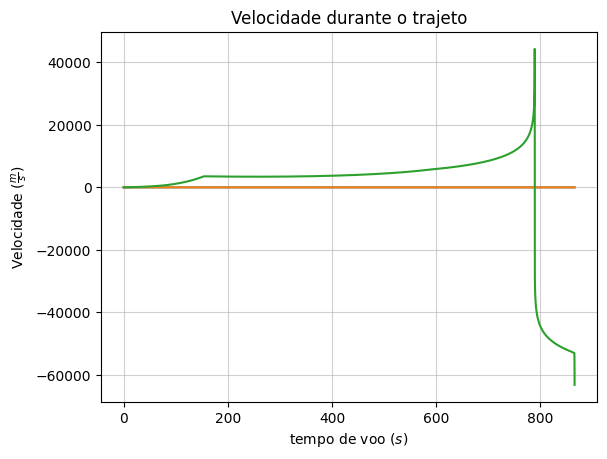

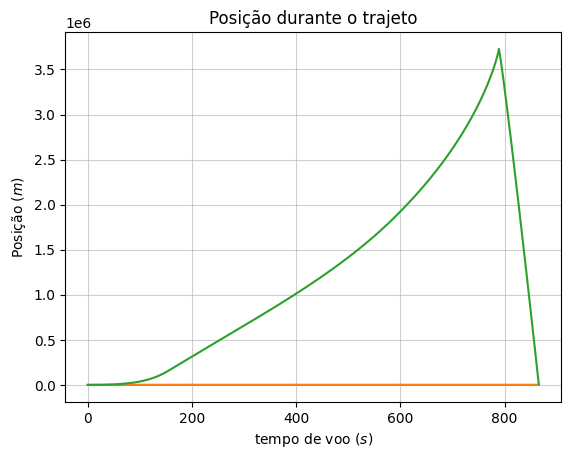

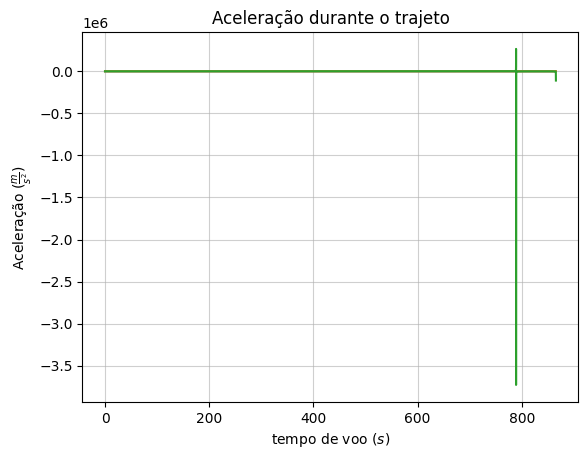

In [141]:
# A linha laranja é pq eu to plotando um vetor, dai são os outros eixos
plt.plot(time,V)

plt.title("Velocidade durante o trajeto")
plt.xlabel(r"tempo de voo ($s$)")
plt.ylabel(r"Velocidade ($\frac{m}{s}$)")

plt.grid(alpha=0.6)
plt.show()

plt.plot(time,R)

plt.title("Posição durante o trajeto")
plt.xlabel(r"tempo de voo ($s$)")
plt.ylabel(r"Posição ($m$)")

plt.grid(alpha=0.6)
plt.show()

plt.plot(time,a)

plt.title("Aceleração durante o trajeto")
plt.xlabel(r"tempo de voo ($s$)")
plt.ylabel(r"Aceleração ($\frac{m}{s^2}$)")

plt.grid(alpha=0.6)
plt.show()